### Problem 11 : Quantum Neural Networks in Qiskit (EstimatorQNN & VQC)

In Problem 10 we trained a variational classifier with PennyLane. Now we build **the same model in
Qiskit** - partly because you will meet both frameworks in the wild, and partly because Qiskit
exposes the machinery in a different and very instructive way.

Qiskit Machine Learning gives you two "quantum neural network" objects :

| | `EstimatorQNN` | `SamplerQNN` |
|---|---|---|
| what it returns | **expectation values** of an observable, e.g. ⟨Z⟩ | **probabilities** of each bitstring |
| output range | [−1, +1] per observable | a probability distribution |
| natural use | regression, ±1 classification | multi-class classification |
| built on | the `Estimator` primitive | the `Sampler` primitive |

Both are just wrappers that say : *"here is a circuit; these parameters are the input data, those
parameters are the weights"*. Everything else - the loss, the optimizer, the fit/predict API - comes
from `NeuralNetworkClassifier`, which deliberately mimics scikit-learn.

**TASK :** Rebuild the Problem 10 classifier with `EstimatorQNN`, train it with a gradient-free
optimizer, and check that we reach the same accuracy.

#### Primitives : Estimator and Sampler

Since Qiskit 1.0 everything talks to hardware and simulators through two **primitives** :

- **Sampler** - "run this circuit N times and tell me how often each bitstring came up".
  This is what `simulator.run(...).get_counts()` did in Problems 1-4.
- **Estimator** - "run this circuit and tell me the expectation value ⟨O⟩ of this observable".
  It handles the basis changes and the averaging for you.

Almost every algorithm in modern Qiskit is written against these two interfaces, which is why
the same code runs on a simulator and on real hardware with one line changed.

In [1]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import real_amplitudes

from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms import NeuralNetworkClassifier, VQC
from qiskit_machine_learning.optimizers import COBYLA

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Step 1: The same dataset as Problem 10, so the comparison is fair
X, y = make_moons(n_samples=200, noise=0.15, random_state=42)
X = StandardScaler().fit_transform(X)
y_pm = 2 * y - 1                 # {-1, +1} labels for EstimatorQNN
                                 # (we keep the original {0, 1} in `y` for the VQC class later)

X_train, X_test, y_train, y_test = train_test_split(X, y_pm, test_size=0.3, random_state=42)
print("Training points:", X_train.shape, " Test points:", X_test.shape)

Training points: (140, 2)  Test points: (60, 2)


#### Building the circuit : two kinds of Parameter

This is the key idea of the whole notebook. A Qiskit circuit can contain **free parameters**, and
we simply *declare which ones are data and which ones are weights* :

- `x = ParameterVector('x', 2)` → the **input** parameters, filled in from each data point.
- the parameters inside `real_amplitudes(...)` → the **weights**, tuned by the optimizer.

`real_amplitudes` is Qiskit's workhorse ansatz : alternating layers of RY rotations and CNOTs.
It is called "real" because, using only RY and CX, every amplitude of the resulting state stays a
real number - a smaller search space that often trains faster.

In [3]:
# Step 2a: The feature map (input parameters) - plain RY angle encoding, as in Problem 10
x = ParameterVector('x', 2)

feature_map = QuantumCircuit(2, name="feature_map")
feature_map.ry(x[0], 0)
feature_map.ry(x[1], 1)

print(feature_map.draw())

     ┌──────────┐
q_0: ┤ Ry(x[0]) ├
     ├──────────┤
q_1: ┤ Ry(x[1]) ├
     └──────────┘


In [4]:
# Step 2b: The ansatz (weight parameters)
ansatz = real_amplitudes(num_qubits=2, reps=3)
print("Trainable weights:", ansatz.num_parameters)
print(ansatz.decompose().draw())

Trainable weights: 8
     ┌─────────────┐     ┌─────────────┐     ┌─────────────┐     »
q_0: ┤ R(θ[0],π/2) ├──■──┤ R(θ[2],π/2) ├──■──┤ R(θ[4],π/2) ├──■──»
     ├─────────────┤┌─┴─┐├─────────────┤┌─┴─┐├─────────────┤┌─┴─┐»
q_1: ┤ R(θ[1],π/2) ├┤ X ├┤ R(θ[3],π/2) ├┤ X ├┤ R(θ[5],π/2) ├┤ X ├»
     └─────────────┘└───┘└─────────────┘└───┘└─────────────┘└───┘»
«     ┌─────────────┐
«q_0: ┤ R(θ[6],π/2) ├
«     ├─────────────┤
«q_1: ┤ R(θ[7],π/2) ├
«     └─────────────┘


In [5]:
# Step 2c: Glue them together into one circuit
qc = QuantumCircuit(2)
qc.compose(feature_map, inplace=True)
qc.compose(ansatz, inplace=True)

qnn = EstimatorQNN(
    circuit=qc,
    input_params=list(x),              # <- these get the data
    weight_params=ansatz.parameters,   # <- these get trained
)

print("Number of inputs :", qnn.num_inputs)
print("Number of weights:", qnn.num_weights)

Number of inputs : 2
Number of weights: 8


By default `EstimatorQNN` measures the parity observable Z⊗Z…⊗Z over all qubits, giving one
number in [−1, +1] - the direct analogue of what we measured in Problem 10.

#### COBYLA : training without gradients

PennyLane used Adam with parameter-shift gradients. Here we use **COBYLA**, a *gradient-free*
optimizer that builds a local linear model of the loss from the values it has already seen.

Why bother with a gradient-free method?

- Each parameter-shift gradient costs **2 extra circuit runs per parameter**. With 8 weights that is
  16 extra jobs for every single step - painful on real hardware where every job queues.
- Measurement results are **noisy**, and finite-difference-style estimates of a noisy function can
  be worse than useless.

The trade-off : COBYLA needs many more *iterations*, and it can stall in local minima. Both styles
are used in practice; gradient-free methods dominate on today's noisy hardware.

In [6]:
# Step 3: Train
objective_values = []

def callback(weights, obj_value):
    objective_values.append(obj_value)

classifier = NeuralNetworkClassifier(
    neural_network=qnn,
    optimizer=COBYLA(maxiter=200),
    loss='squared_error',
    callback=callback,
)

print("Training... (this takes a minute or so)")
classifier.fit(X_train, y_train)
print("Done.")

Training... (this takes a minute or so)


Done.


Training accuracy: 0.857
Test accuracy    : 0.833


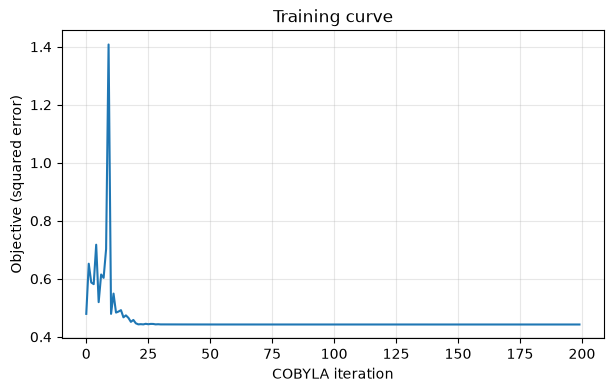

In [7]:
# Step 4: Evaluate
print(f"Training accuracy: {classifier.score(X_train, y_train):.3f}")
print(f"Test accuracy    : {classifier.score(X_test, y_test):.3f}")

plt.figure(figsize=(7, 4))
plt.plot(objective_values)
plt.xlabel("COBYLA iteration"); plt.ylabel("Objective (squared error)")
plt.title("Training curve"); plt.grid(alpha=0.3); plt.show()

#### The shortcut : the `VQC` class

Everything above - feature map, ansatz, QNN, classifier - is bundled into a single Qiskit class
called `VQC`. It uses a `SamplerQNN` under the hood, one-hot encodes the labels, and applies
cross-entropy loss, so it expects the **original {0, 1} labels** rather than ±1.

Use `VQC` when you want the standard recipe; drop down to `EstimatorQNN` when you want to choose
your own observable, loss, or output shape.

In [8]:
X_train_01, X_test_01, y_train_01, y_test_01 = train_test_split(
    X, y, test_size=0.3, random_state=42          # note: the original {0, 1} labels
)

vqc = VQC(
    feature_map=feature_map,
    ansatz=real_amplitudes(num_qubits=2, reps=3),
    optimizer=COBYLA(maxiter=200),
)

print("Training the VQC class...")
vqc.fit(X_train_01, y_train_01)

print(f"VQC training accuracy: {vqc.score(X_train_01, y_train_01):.3f}")
print(f"VQC test accuracy    : {vqc.score(X_test_01, y_test_01):.3f}")

Training the VQC class...


VQC training accuracy: 0.843
VQC test accuracy    : 0.800


#### OUTCOME :

Three routes - PennyLane + Adam (Problem 10), Qiskit `EstimatorQNN` + COBYLA, and Qiskit `VQC` -
all land in the same place, **roughly 82-85%**.

That agreement is the real result of this notebook. The framework, the optimizer and the loss
function were all different, yet the ceiling did not move. When three independent training setups
plateau at the same number, the limit is not the training - it is **the model**. Specifically it is
the feature map, which encodes each data point exactly once.

#### Key Takeaways :
- Qiskit expresses a QNN as *one circuit* with parameters split into `input_params` and `weight_params`.
- `EstimatorQNN` → expectation values; `SamplerQNN` → probability distributions.
- `NeuralNetworkClassifier` gives you a scikit-learn style `fit` / `predict` / `score`.
- Gradient-free optimizers like COBYLA are the practical default on noisy hardware.
- If several different optimizers all plateau at the same accuracy, **change the model, not the optimizer**.

#### TASK :
1. Swap the RY feature map for `zz_feature_map(2, reps=2)` from Problem 9. The accuracy gets
   *worse* on the moons - why might an entangling feature map hurt on a dataset whose classes are
   defined by a simple 2D shape?
2. Raise `COBYLA(maxiter=...)` to 500. Does the extra budget help, or does the training curve go
   flat long before that?
3. Replace `real_amplitudes` with `efficient_su2` (also in `qiskit.circuit.library`). It has more
   parameters per layer - measure the accuracy *and* the training time.